In [5]:
from forecast import load_prices, train_test_split_time, build_features, seasonal_naive_forecast, mae

prices = load_prices()
features = build_features(prices)
train_f, test_f = train_test_split_time(features, test_weeks=8)

# Only lags of 24h or more - a 1-hour lag isn't something a real day-ahead forecast
# could ever use (see forecast.py's build_features docstring for why).
feature_cols = ["hour", "dayofweek", "month", "is_weekend", "lag_24h", "lag_48h", "lag_168h"]
target_col = "price_eur_mwh"

# Drop rows with missing lag history - this only affects the first week of the
# whole dataset (well inside the training period), because features were built on
# the full series before splitting, same discipline as the baseline notebook.
train_f = train_f.dropna(subset=feature_cols + [target_col])
print(f"train: {len(train_f)} rows (after dropping rows with no lag history yet)")
print(f"test:  {len(test_f)} rows, any missing features: {test_f[feature_cols].isna().any().any()}")

train: 7152 rows (after dropping rows with no lag history yet)
test:  1344 rows, any missing features: False


In [6]:
from sklearn.ensemble import GradientBoostingRegressor
import pandas as pd

X_train, y_train = train_f[feature_cols], train_f[target_col]
X_test, y_test = test_f[feature_cols], test_f[target_col]

model = GradientBoostingRegressor(random_state=42)
model.fit(X_train, y_train)
gbm_predictions = pd.Series(model.predict(X_test), index=X_test.index)

gbm_mae = mae(y_test, gbm_predictions)
baseline_mae = mae(test_f[target_col], seasonal_naive_forecast(prices).loc[test_f.index])

print(f"Baseline (seasonal naive) MAE: {baseline_mae:.2f} EUR/MWh")
print(f"Gradient boosting MAE:         {gbm_mae:.2f} EUR/MWh")
print(f"Improvement over baseline:     {100 * (baseline_mae - gbm_mae) / baseline_mae:.1f}%")

Baseline (seasonal naive) MAE: 53.53 EUR/MWh
Gradient boosting MAE:         41.19 EUR/MWh
Improvement over baseline:     23.0%


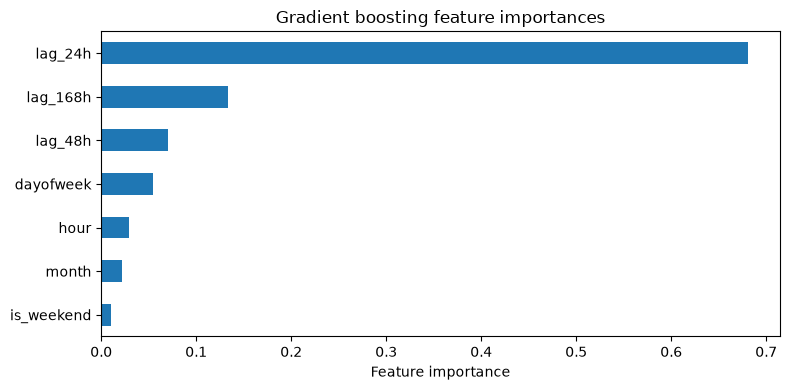

lag_24h       0.680451
lag_168h      0.133949
lag_48h       0.069918
dayofweek     0.054361
hour          0.029720
month         0.021670
is_weekend    0.009930
dtype: float64


In [7]:
import matplotlib.pyplot as plt

# Which features is the model actually relying on? lag_24h dominating over lag_168h
# would mean "yesterday" is a stronger signal than "last week" - something the
# seasonal-naive baseline had no way to use, since it only ever looks a week back.
importances = pd.Series(model.feature_importances_, index=feature_cols).sort_values()
plt.figure(figsize=(8, 4))
importances.plot.barh()
plt.xlabel("Feature importance")
plt.title("Gradient boosting feature importances")
plt.tight_layout()
plt.show()
print(importances.sort_values(ascending=False))

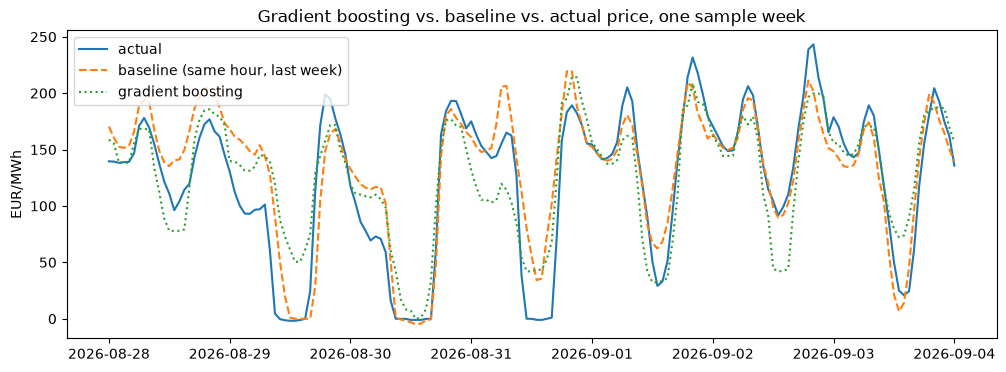

In [8]:
# Same sample week as the baseline notebook, now with both forecasts overlaid,
# so the improvement is visible, not just a number.
naive_forecast_test = seasonal_naive_forecast(prices).loc[test_f.index]

sample_start = test_f.index.min() + pd.Timedelta(days=7)
sample_end = sample_start + pd.Timedelta(days=7)
sample_actual = y_test.loc[sample_start:sample_end]
sample_baseline = naive_forecast_test.loc[sample_start:sample_end]
sample_gbm = gbm_predictions.loc[sample_start:sample_end]

plt.figure(figsize=(12, 4))
plt.plot(sample_actual.index, sample_actual, label="actual")
plt.plot(sample_baseline.index, sample_baseline, label="baseline (same hour, last week)", linestyle="--")
plt.plot(sample_gbm.index, sample_gbm, label="gradient boosting", linestyle=":")
plt.ylabel("EUR/MWh")
plt.legend()
plt.title("Gradient boosting vs. baseline vs. actual price, one sample week")
plt.show()